Imagine you manage a small supermarket. You have recorded the number of products sold each day, and you want to predict how many products you might sell tomorrow.
- Input: Sales from the previous 7 days.
- Model: LSTM neural network.
- Output: Predicted sales for the next day.
- Goal: Help the shop plan its stock.
For example, if the previous 7 days' sales were [100, 110, 105, 120, 130, 125, 140], the LSTM uses this sequence to predict the next day's sales.


        Date  Sales
0 2025-01-01     82
1 2025-01-02     88
2 2025-01-03     93
3 2025-01-04     92
4 2025-01-05     76


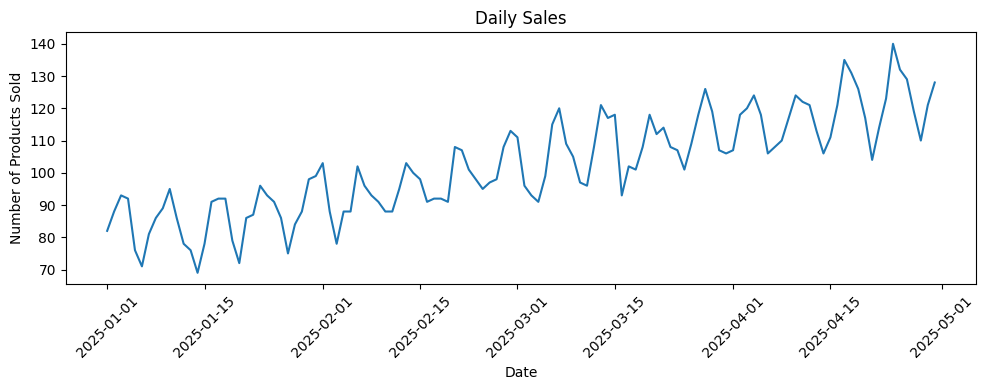

Training samples: 89
Testing samples: 24


c:\Users\arifv\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0902
Epoch 2/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0201 
Epoch 3/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0237 
Epoch 4/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0230 
Epoch 5/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0215 
Epoch 6/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0207 
Epoch 7/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0210 
Epoch 8/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0209 
Epoch 9/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0205 
Epoch 10/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0204
Epoch 11/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0203 
Epoch 12/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0201 
Epoch 13/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0199 
Epoch 14/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0198 
Epoch 15/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0196 
Epoch 

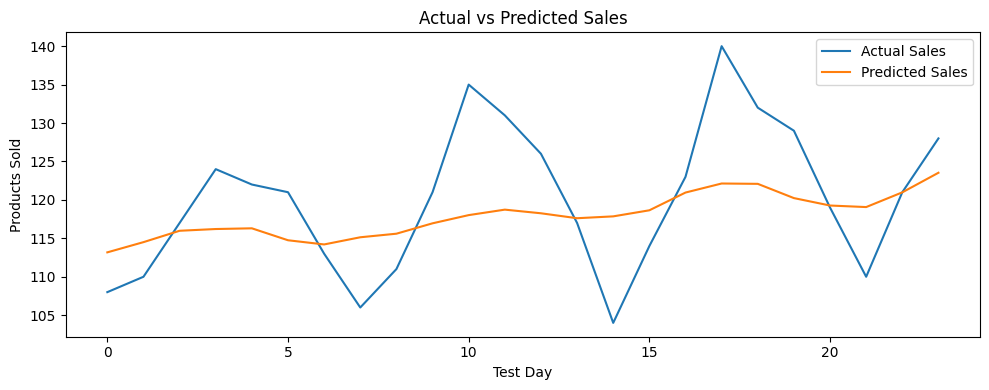


Predicted sales for the next day: 125


In [1]:

# ==========================================
# PROJECT: DAILY SALES FORECASTING USING LSTM
# ==========================================

# Step 1: Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

# Step 2: Load the dataset
df = pd.read_csv("daily_sales_lstm.csv")

# Convert Date column into datetime format
df["Date"] = pd.to_datetime(df["Date"])

# Display first five rows
print(df.head())

# Step 3: Visualize daily sales
plt.figure(figsize=(10, 4))
plt.plot(df["Date"], df["Sales"])
plt.title("Daily Sales")
plt.xlabel("Date")
plt.ylabel("Number of Products Sold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Step 4: Extract sales values
sales = df[["Sales"]].values.astype("float32")

# Step 5: Scale data between 0 and 1
# Fit the scaler only on the training data to avoid leakage.
split_index = int(len(sales) * 0.8)

scaler = MinMaxScaler(feature_range=(0, 1))
scaler.fit(sales[:split_index])

scaled_sales = scaler.transform(sales)

# Step 6: Create sequences
# Use the previous 7 days to predict the next day.

X =[]
Y =[]
window_size=7
for i in range(len(scaled_sales)-window_size):
    X.append(scaled_sales[i:i+window_size])
    Y.append(scaled_sales[i+window_size])


X = np.array(X)
Y = np.array(Y)

# Step 7: Split into training and testing sets
# Keep the time order; do not shuffle time-series data.
train_end = split_index - 7

X_train = X[:train_end]
y_train = Y[:train_end]

X_test = X[train_end:]
y_test = Y[train_end:]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

# Step 8: Build the LSTM model
model = Sequential([
    LSTM(32, input_shape=(7, 1)),
    Dense(1)
])

# Step 9: Compile the model
model.compile(
    optimizer="adam",
    loss="mean_squared_error"
)

# Step 10: Train the model
model.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=8,
    shuffle=False,
    verbose=1
)

# Step 11: Predict test-set sales
predictions = model.predict(X_test, verbose=0)

# Convert scaled values back to sales units
predicted_sales = scaler.inverse_transform(predictions)
actual_sales = scaler.inverse_transform(y_test)

# Step 12: Evaluate the model
mae = mean_absolute_error(actual_sales, predicted_sales)
rmse = np.sqrt(mean_squared_error(actual_sales, predicted_sales))

print("\nModel Evaluation")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))

# Step 13: Compare actual and predicted sales
plt.figure(figsize=(10, 4))

plt.plot(actual_sales, label="Actual Sales")
plt.plot(predicted_sales, label="Predicted Sales")

plt.title("Actual vs Predicted Sales")
plt.xlabel("Test Day")
plt.ylabel("Products Sold")
plt.legend()
plt.tight_layout()
plt.show()

# Step 14: Predict sales for the next day
last_7_days = scaled_sales[-7:]
last_7_days = last_7_days.reshape(1, 7, 1)

next_day_scaled = model.predict(last_7_days, verbose=0)
next_day_sales = scaler.inverse_transform(next_day_scaled)

print(
    "\nPredicted sales for the next day:",
    round(float(next_day_sales[0, 0]))
)
